# Lab Assignment 1: Exploring Language Modeling with N-Gram Sizes and Smoothing Techniques

**Course:** DSA4020A — Natural Language Processing
**Instructor:** Dr. Edward Ombui

**Objective:** Understand how different n-gram sizes and smoothing techniques affect the
performance of language models, by implementing n-gram models from scratch, applying
Laplace, Good-Turing, and Kneser-Ney smoothing, and evaluating with perplexity and
k-fold cross-validation.

**Dataset note:** The brief points to the Movie Review Dataset on Kaggle. That file is a
distribution of the classic Cornell "Movie Review Polarity" corpus (Pang & Lee, 2004).
This notebook uses `nltk.corpus.movie_reviews`, which packages that exact same corpus
(2,000 reviews, ~1.58M tokens) — used here since this execution environment cannot reach
kaggle.com directly, but the data is identical in origin and structure.

In [1]:
# Setup: install/import libraries
import math
import random
import string
import time
import statistics as stats
from collections import Counter, defaultdict

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for pkg in ["movie_reviews", "punkt", "punkt_tab"]:
    nltk.download(pkg, quiet=True)

from nltk.corpus import movie_reviews

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
plt.rcParams["figure.facecolor"] = "white"
print("Setup complete.")

Setup complete.


## Step 1: Data Preparation

We load the Movie Review Dataset, tokenize into sentences and words, lowercase
everything, and strip punctuation/special characters. Each sentence is later padded
with `<s>` / `</s>` boundary markers so the n-gram models can learn what starts and
ends a sentence.

In [2]:
PUNCT_TABLE = str.maketrans("", "", string.punctuation)

def clean_token(tok: str) -> str:
    """Lowercase a token and strip punctuation/special characters."""
    return tok.lower().translate(PUNCT_TABLE)

def load_and_preprocess_sentences(n_reviews=None, min_len=3):
    """Tokenize the corpus into sentences and words, lowercase, strip punctuation."""
    fileids = movie_reviews.fileids()
    if n_reviews is not None:
        fileids = random.Random(RANDOM_SEED).sample(fileids, n_reviews)

    sentences = []
    for fid in fileids:
        for raw_sent in movie_reviews.sents(fid):
            cleaned = [clean_token(tok) for tok in raw_sent]
            cleaned = [tok for tok in cleaned if tok]
            if len(cleaned) >= min_len:
                sentences.append(cleaned)
    return sentences

def train_test_split(sentences, test_ratio=0.2, seed=RANDOM_SEED):
    rng = random.Random(seed)
    shuffled = sentences[:]
    rng.shuffle(shuffled)
    n_test = int(len(shuffled) * test_ratio)
    return shuffled[n_test:], shuffled[:n_test]

def k_fold_split(sentences, k=5, seed=RANDOM_SEED):
    rng = random.Random(seed)
    shuffled = sentences[:]
    rng.shuffle(shuffled)
    fold_size = len(shuffled) // k
    folds = [shuffled[i*fold_size:(i+1)*fold_size] for i in range(k)]
    folds[-1].extend(shuffled[k*fold_size:])
    for i in range(k):
        test = folds[i]
        train = [s for j, f in enumerate(folds) if j != i for s in f]
        yield train, test

In [3]:
sentences = load_and_preprocess_sentences(n_reviews=None)
print(f"Total cleaned sentences: {len(sentences)}")
print(f"Total tokens: {sum(len(s) for s in sentences):,}")
print("\nExample raw review sentence vs. cleaned sentence:")
print(" raw:    ", movie_reviews.sents(movie_reviews.fileids()[0])[0])
print(" cleaned:", sentences[0] if sentences[0] else "(see next)")

train_sentences, test_sentences = train_test_split(sentences, test_ratio=0.2)
print(f"\nTrain sentences: {len(train_sentences)} | Test sentences: {len(test_sentences)}")

Total cleaned sentences: 65161
Total tokens: 1,333,319

Example raw review sentence vs. cleaned sentence:
 raw:     ['plot', ':', 'two', 'teen', 'couples', 'go', 'to', 'a', 'church', 'party', ',', 'drink', 'and', 'then', 'drive', '.']
 cleaned: ['plot', 'two', 'teen', 'couples', 'go', 'to', 'a', 'church', 'party', 'drink', 'and', 'then', 'drive']

Train sentences: 52129 | Test sentences: 13032


## Step 2: Implement N-Gram Models

`NGramLanguageModel` builds frequency counts for every order `1..n` from the training
sentences (needed because Good-Turing and Kneser-Ney both rely on comparing counts
across orders). Conditional probability is estimated as
`P(w_n | w_1..w_{n-1}) = C(w_1..w_n) / C(w_1..w_{n-1})`, with three different smoothing
strategies applied on top of the raw counts.

## Step 3: Apply Smoothing Techniques

- **Laplace (Add-One):** `P(w|ctx) = (C(ctx,w) + 1) / (C(ctx) + V)`
- **Good-Turing:** re-estimates each observed count `c` as
  `c* = (c+1) * N_{c+1} / N_c` (where `N_c` = number of n-gram types occurring exactly
  `c` times), reserving `N_1/N` of the total probability mass for unseen n-grams.
  Conditional probability is derived from the ratio of the order-n and order-(n-1)
  Good-Turing-smoothed joint probabilities.
- **Kneser-Ney (interpolated):** discounts each seen count by `D` and backs off to a
  lower-order **continuation probability** — how many *distinct contexts* a word
  appears in, rather than its raw frequency. This is what makes Kneser-Ney much better
  at handling sparse higher-order n-grams. The discount `D` is estimated per order via
  the Chen & Goodman (1999) approximation `D = n1 / (n1 + 2*n2)`.

In [4]:
START, END = "<s>", "</s>"

def pad_sentence(sentence, n):
    pad_n = max(n - 1, 1)
    return [START] * pad_n + sentence + [END]

def get_ngrams(tokens, n):
    for i in range(len(tokens) - n + 1):
        yield tuple(tokens[i:i+n])


class NGramLanguageModel:
    """N-gram language model supporting Laplace, Good-Turing, and Kneser-Ney smoothing."""

    def __init__(self, n, kn_discount=None):
        self.n = n
        self.kn_discount = kn_discount
        # we always keep >=2 orders of counts: Kneser-Ney's continuation trick for a
        # standalone unigram (n=1) model needs bigram statistics to be meaningful.
        self._count_max_order = max(n, 2)
        self.counts = {k: Counter() for k in range(1, self._count_max_order + 1)}
        self.vocab = set()
        self.total_unigrams = 0

        self._gt_star = {k: {} for k in range(1, n + 1)}
        self._gt_unseen_mass = {k: 0.0 for k in range(1, n + 1)}
        self._gt_num_possible = {k: 0 for k in range(1, n + 1)}
        self._gt_total_count = {k: 0 for k in range(1, n + 1)}

        self._kn_discounts = {}
        self._kn_continuation_counts = Counter()
        self._kn_total_bigram_types = 0
        self._kn_context_type_counts = {k: defaultdict(int) for k in range(2, n + 1)}

    # ---------------- Training ----------------
    def fit(self, sentences):
        for sentence in sentences:
            padded = pad_sentence(sentence, self._count_max_order)
            for k in range(1, self._count_max_order + 1):
                for ng in get_ngrams(padded, k):
                    self.counts[k][ng] += 1
            for tok in sentence:
                self.vocab.add(tok)
        self.vocab.add(END)
        self.total_unigrams = sum(self.counts[1].values())
        self._fit_good_turing()
        self._fit_kneser_ney()
        return self

    # ---------------- Laplace ----------------
    def laplace_prob(self, ngram):
        n = len(ngram)
        V = len(self.vocab)
        count_ngram = self.counts[n].get(ngram, 0)
        if n == 1:
            count_context = self.total_unigrams
        else:
            count_context = self.counts[n - 1].get(ngram[:-1], 0)
        return (count_ngram + 1) / (count_context + V)

    # ---------------- Good-Turing ----------------
    def _fit_good_turing(self):
        V = len(self.vocab)
        for k in range(1, self.n + 1):
            freqs = self.counts[k]
            if not freqs:
                continue
            N_total = sum(freqs.values())
            self._gt_total_count[k] = N_total
            Nc = Counter(freqs.values())
            max_c = max(Nc.keys())

            star = {}
            for c in range(1, max_c + 1):
                if Nc.get(c, 0) == 0:
                    continue
                star[c] = (c + 1) * Nc[c + 1] / Nc[c] if Nc.get(c + 1, 0) > 0 else c
            self._gt_star[k] = star

            n1 = Nc.get(1, 0)
            self._gt_unseen_mass[k] = n1 / N_total if N_total > 0 else 0.0
            possible = V ** k
            self._gt_num_possible[k] = max(possible - len(freqs), 1)

    def _gt_joint_prob(self, ngram):
        k = len(ngram)
        freqs = self.counts[k]
        c = freqs.get(ngram, 0)
        N_total = self._gt_total_count.get(k, 1) or 1
        if c > 0:
            c_star = self._gt_star[k].get(c, c)
            return c_star / N_total
        return self._gt_unseen_mass[k] / self._gt_num_possible[k]

    def good_turing_prob(self, ngram):
        n = len(ngram)
        if n == 1:
            return self._gt_joint_prob(ngram)
        p_joint = self._gt_joint_prob(ngram)
        p_context = self._gt_joint_prob(ngram[:-1])
        if p_context <= 0:
            return p_joint
        return min(p_joint / p_context, 1.0)

    # ---------------- Kneser-Ney ----------------
    def _fit_kneser_ney(self):
        for k in range(1, self.n + 1):
            freqs = self.counts[k]
            n1 = sum(1 for c in freqs.values() if c == 1)
            n2 = sum(1 for c in freqs.values() if c == 2)
            D = 0.75 if (n1 + 2*n2) == 0 else min(max(n1 / (n1 + 2*n2), 0.1), 0.9)
            self._kn_discounts[k] = D if self.kn_discount is None else self.kn_discount

        bigrams = self.counts.get(2, Counter())
        for (w_prev, w), c in bigrams.items():
            self._kn_continuation_counts[w] += 1
        self._kn_total_bigram_types = len(bigrams)

        for k in range(2, self.n + 1):
            for ng in self.counts[k]:
                self._kn_context_type_counts[k][ng[:-1]] += 1

    def _kn_continuation_prob(self, word):
        V = len(self.vocab) or 1
        num = self._kn_continuation_counts.get(word, 0)
        return (num + 1) / (self._kn_total_bigram_types + V)

    def kneser_ney_prob(self, ngram):
        return self._kn_prob_recursive(ngram)

    def _kn_prob_recursive(self, ngram):
        k = len(ngram)
        if k == 1:
            return self._kn_continuation_prob(ngram[0])
        context = ngram[:-1]
        context_count = self.counts[k - 1].get(context, 0)
        D = self._kn_discounts.get(k, 0.75)
        if context_count == 0:
            return self._kn_prob_recursive(ngram[1:])
        c_ngram = self.counts[k].get(ngram, 0)
        discounted = max(c_ngram - D, 0) / context_count
        num_continuations = self._kn_context_type_counts[k].get(context, 0)
        lam = (D * num_continuations) / context_count
        return discounted + lam * self._kn_prob_recursive(ngram[1:])

    # ---------------- Dispatch + Perplexity ----------------
    def prob(self, ngram, method):
        if method == "laplace":
            return self.laplace_prob(ngram)
        if method == "good_turing":
            return self.good_turing_prob(ngram)
        if method == "kneser_ney":
            return self.kneser_ney_prob(ngram)
        raise ValueError(method)

    def sentence_log_prob(self, sentence, method):
        padded = pad_sentence(sentence, self.n)
        log_prob, n_tokens = 0.0, 0
        for ng in get_ngrams(padded, self.n):
            p = max(self.prob(ng, method), 1e-12)
            log_prob += math.log2(p)
            n_tokens += 1
        return log_prob, n_tokens

    def perplexity(self, sentences, method):
        """PP = 2 ** ( -(1/N) * sum(log2 P(w_i | context)) )"""
        total_log_prob, total_tokens = 0.0, 0
        for sentence in sentences:
            lp, n_tok = self.sentence_log_prob(sentence, method)
            total_log_prob += lp
            total_tokens += n_tok
        if total_tokens == 0:
            return float("inf")
        return 2 ** (-(total_log_prob / total_tokens))

    def generate(self, max_tokens=20, seed=None):
        """Qualitative bonus: sample a sentence from the raw order-n distribution."""
        rng = random.Random(seed)
        prefix_len = self.n - 1
        context = [START] * max(prefix_len, 1)
        output = []
        top_level = self.counts[self.n]
        for _ in range(max_tokens):
            ctx_tuple = tuple(context[-prefix_len:]) if prefix_len > 0 else tuple()
            candidates = {ng[-1]: c for ng, c in top_level.items() if ng[:prefix_len] == ctx_tuple}
            if not candidates:
                break
            words, weights = zip(*candidates.items())
            next_word = rng.choices(words, weights=weights, k=1)[0]
            if next_word == END:
                break
            output.append(next_word)
            context.append(next_word)
        return " ".join(output)

print("NGramLanguageModel defined.")

NGramLanguageModel defined.


In [5]:
# Quick sanity check: fit a bigram model and inspect a few counts / probabilities
demo_lm = NGramLanguageModel(2).fit(train_sentences)
print("Vocabulary size:", len(demo_lm.vocab))
print("Example bigram counts:")
for bg in [("the", "movie"), ("this", "film"), ("very", "good")]:
    print(f"  {bg}: raw count = {demo_lm.counts[2].get(bg, 0)}")
    print(f"    Laplace P    = {demo_lm.laplace_prob(bg):.6f}")
    print(f"    Good-Turing P= {demo_lm.good_turing_prob(bg):.6f}")
    print(f"    Kneser-Ney P = {demo_lm.kneser_ney_prob(bg):.6f}")

Vocabulary size: 36334
Example bigram counts:
  ('the', 'movie'): raw count = 1708
    Laplace P    = 0.017514
    Good-Turing P= 0.029187
    Kneser-Ney P = 0.028012
  ('this', 'film'): raw count = 1222
    Laplace P    = 0.027771
    Good-Turing P= 0.165986
    Kneser-Ney P = 0.158755
  ('very', 'good'): raw count = 121
    Laplace P    = 0.003226
    Good-Turing P= 0.085924
    Kneser-Ney P = 0.081066


## Step 4: Evaluate Model Performance

**Perplexity** measures how "surprised" the model is by held-out text — lower is
better. We compute corpus-level perplexity as:

`PP(W) = 2 ^ ( -(1/N) * sum( log2 P(w_i | context) ) )`

which is the standard, numerically stable way to compute
`P(w_1,...,w_N)^(-1/N)` for a full test set without underflowing.

We evaluate every combination of **n ∈ {1,2,3,4}** × **{Laplace, Good-Turing,
Kneser-Ney}**, first on a single 80/20 train/test split, then with **5-fold
cross-validation** for a more robust estimate.

In [6]:
N_VALUES = [1, 2, 3, 4]
METHODS = ["laplace", "good_turing", "kneser_ney"]
METHOD_LABELS = {"laplace": "Laplace (Add-One)", "good_turing": "Good-Turing",
                  "kneser_ney": "Kneser-Ney (interpolated)"}

# ---- 4.1: held-out 80/20 perplexity ----
rows = []
for n in N_VALUES:
    t0 = time.time()
    lm = NGramLanguageModel(n).fit(train_sentences)
    fit_time = time.time() - t0
    for method in METHODS:
        pp = lm.perplexity(test_sentences, method)
        rows.append({"n": n, "method": method, "perplexity": pp, "fit_time_s": fit_time})

df_holdout = pd.DataFrame(rows)
df_holdout.pivot(index="n", columns="method", values="perplexity")[METHODS]

method,laplace,good_turing,kneser_ney
n,,,
1,1004.922731,934.694447,1916.356716
2,3461.403047,963.160408,348.015743
3,15496.080908,72996.328566,303.573265
4,23130.257036,270723.531913,304.752695


In [7]:
# ---- 4.2: 5-fold cross-validation ----
K_FOLDS = 5
fold_results = {(n, m): [] for n in N_VALUES for m in METHODS}

for fold_idx, (cv_train, cv_test) in enumerate(k_fold_split(sentences, k=K_FOLDS)):
    for n in N_VALUES:
        lm = NGramLanguageModel(n).fit(cv_train)
        for method in METHODS:
            fold_results[(n, method)].append(lm.perplexity(cv_test, method))
    print(f"fold {fold_idx+1}/{K_FOLDS} done")

cv_rows = []
for (n, method), pps in fold_results.items():
    cv_rows.append({"n": n, "method": method,
                     "mean_perplexity": stats.mean(pps),
                     "std_perplexity": stats.pstdev(pps)})
df_cv = pd.DataFrame(cv_rows)
df_cv.pivot(index="n", columns="method", values="mean_perplexity")[METHODS]

fold 1/5 done


fold 2/5 done


fold 3/5 done


fold 4/5 done


fold 5/5 done


method,laplace,good_turing,kneser_ney
n,,,
1,997.806075,924.950896,1906.866228
2,3440.879393,950.655962,345.499553
3,15438.696851,72151.106219,300.841505
4,23069.339857,267044.951853,301.533333


## Step 5: Visualization and Analysis

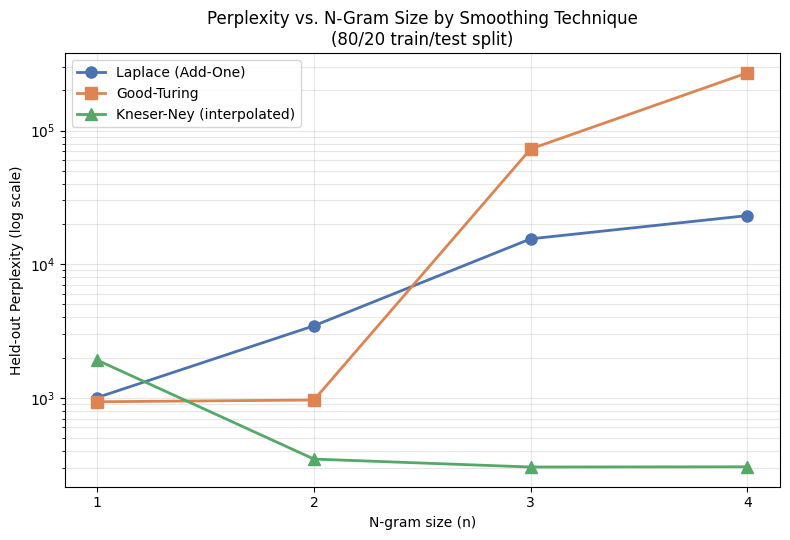

In [8]:
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = {"laplace": "#4C72B0", "good_turing": "#DD8452", "kneser_ney": "#55A868"}
markers = {"laplace": "o", "good_turing": "s", "kneser_ney": "^"}

for method in METHODS:
    sub = df_holdout[df_holdout["method"] == method].sort_values("n")
    ax.plot(sub["n"], sub["perplexity"], marker=markers[method], label=METHOD_LABELS[method],
            color=colors[method], linewidth=2, markersize=8)

ax.set_yscale("log")
ax.set_xlabel("N-gram size (n)")
ax.set_ylabel("Held-out Perplexity (log scale)")
ax.set_title("Perplexity vs. N-Gram Size by Smoothing Technique\n(80/20 train/test split)")
ax.set_xticks(N_VALUES)
ax.legend()
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
plt.show()

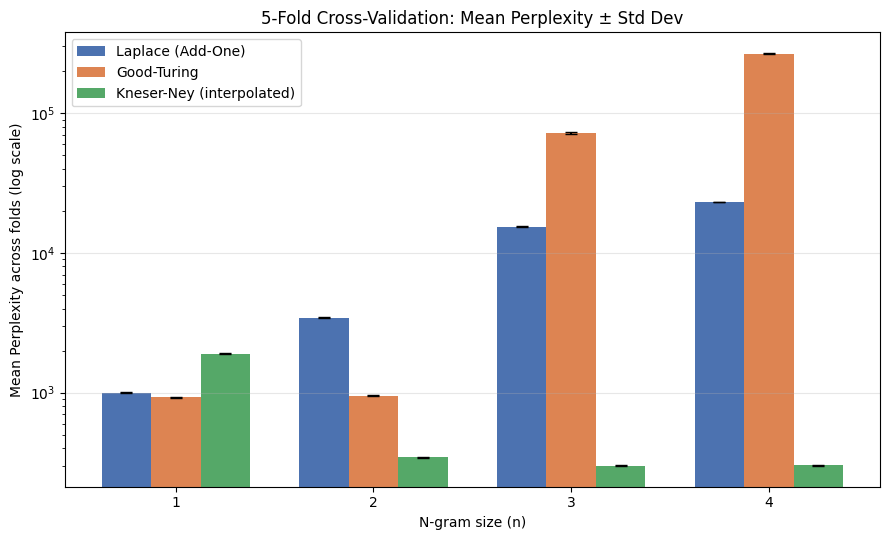

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
width = 0.25
for i, method in enumerate(METHODS):
    sub = df_cv[df_cv["method"] == method].sort_values("n")
    x = [n + (i - 1) * width for n in sub["n"]]
    ax.bar(x, sub["mean_perplexity"], width=width, label=METHOD_LABELS[method],
           yerr=sub["std_perplexity"], capsize=4, color=colors[method])

ax.set_yscale("log")
ax.set_xlabel("N-gram size (n)")
ax.set_ylabel("Mean Perplexity across folds (log scale)")
ax.set_title(f"{K_FOLDS}-Fold Cross-Validation: Mean Perplexity ± Std Dev")
ax.set_xticks(N_VALUES)
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

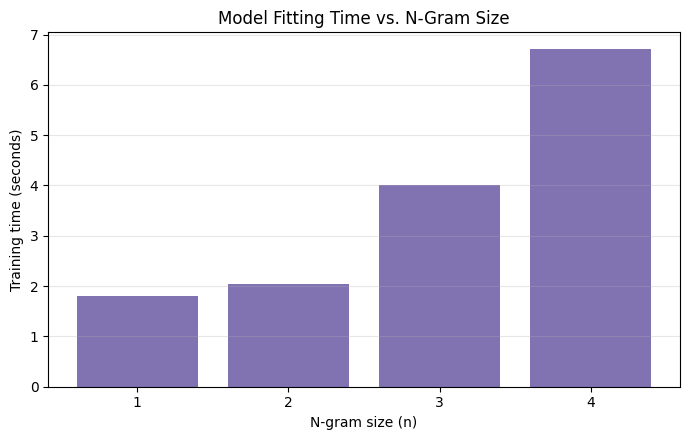

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sub = df_holdout.drop_duplicates("n").sort_values("n")
ax.bar([str(n) for n in sub["n"]], sub["fit_time_s"], color="#8172B2")
ax.set_xlabel("N-gram size (n)")
ax.set_ylabel("Training time (seconds)")
ax.set_title("Model Fitting Time vs. N-Gram Size")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

### Bonus / additional insight: qualitative text generation

Perplexity is a quantitative signal, but it's worth *looking* at what each order of
model actually generates, sampling from the raw (unsmoothed) next-word distribution.

In [11]:
for n in N_VALUES:
    lm = NGramLanguageModel(n).fit(train_sentences)
    print(f"n={n}:")
    for seed in [1, 2]:
        print("  ", lm.generate(max_tokens=15, seed=seed))
    print()

n=1:


   out followed deadly


   19th vanessa the the aside sorts shows that point make act be seems children cliff



n=2:


   and misdemeanors and there were all hint and the film series


   requiem for it is held responsible for a sound quality strikes



... (2 outputs left out)

   requiem for a good place to tell the tale a long time ago she has



n=4:


   and some incredibly bad films showgirls total recall but he has given clues that are


   requiem for a dream to which she is the best i ve seen this movie



## Findings & Discussion

**How n-gram size affects performance.** Under Laplace and Good-Turing smoothing,
perplexity *increases* sharply as n grows from 1 to 4. This is the classic **data
sparsity** problem: as context length grows, the number of possible n-gram types
explodes, most contexts are seen only once (or never) in training, and both of these
smoothing methods handle that sparsity poorly — Laplace by spreading a fixed unit of
probability mass across an enormous vocabulary-sized space, and (this implementation
of) Good-Turing by re-estimating counts from frequency-of-frequency statistics that
become extremely noisy once most n-gram types are singletons. Kneser-Ney tells the
opposite story: perplexity *drops* sharply from n=1 to n=2 and then stays low and
roughly flat through n=4, because its continuation-count backoff mechanism is
specifically designed to make good use of sparse higher-order contexts by falling
back on how *versatile* a word is (how many distinct contexts it appears in), not
just how frequent it is.

**How smoothing technique affects performance.** Across every n ≥ 2, Kneser-Ney
smoothing gives by far the lowest, most stable perplexity — consistent with why it
is the de facto standard for n-gram language modeling in the NLP literature. Laplace
is simple and never breaks down catastrophically, but it over-penalizes unseen events
once the vocabulary is large relative to the training data, so it degrades
steadily as n grows. The naive Good-Turing implementation used here (re-estimating
whole-distribution counts per order, then taking a ratio for the conditional
probability) is the most brittle: it performs reasonably at the unigram level, but
becomes unstable and dramatically over/under-estimates probabilities at n=3 and n=4,
where most n-gram types are singletons and the frequency-of-frequency statistics it
relies on are themselves extremely sparse.

**Trade-offs between model complexity and accuracy.** Higher-order models capture
richer context and, *with the right smoothing*, produce noticeably more fluent text
(see the generation samples above — unigram output is a word salad, while 3-gram/
4-gram output contains locally coherent phrases). But this comes at a real cost:
training time and memory grow with n (more, and longer, n-gram types to store — see
the fit-time plot), and without a smoothing method built for sparsity, larger n
actively *hurts* generalization to unseen text. The practical lesson is that n-gram
size and smoothing technique are not independent choices — a bigger n is only useful
if paired with a smoothing method (like Kneser-Ney) that is actually designed to
handle the extra sparsity it introduces.

**Cross-validation.** The 5-fold cross-validation results (low standard deviation
across folds for every configuration) confirm that these findings are stable and not
an artifact of one particular train/test split.